# Part VI — The verdict: model against reality
**Question:** *could we have predicted the 2026 season, race by race?* Before each 2026 race, every model is re-trained on everything that happened before it (PCA and k-means included), exactly like a live forecast. Then we compare with what really happened.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1duel.data import build, TEAM_STATS
from f1duel.plots import style, title, save, BLUE, ORANGE, AQUA, GREY, INK, INK2, MUTED, TIER_COLORS
style(); pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
d = build()
import json
S = json.load(open('../results/summary.json')); P = pd.read_csv('../results/predictions.csv')
from f1duel.model import scorers_named, pick10
Q = P[P.test == '2026']
rows = []
for (r, gp), g in Q.groupby(['round', 'gp_name']):
    fav = g.loc[g.p_win.idxmax()]; win = g[g.win == 1]
    rows.append({'Round': r, 'Grand Prix': gp,
                 'Grid rule': int(g.top10[pick10(g, 'grid', True) == 1].sum()),
                 'Model': int(g.top10[pick10(g, 'p_top10_logit') == 1].sum()),
                 'Model favourite': f"{fav.driver_name} ({fav.p_win:.0%})",
                 'Real winner': win.driver_name.iloc[0] if len(win) else '—'})
T = pd.DataFrame(rows).set_index('Round'); T

,Grand Prix,Grid rule,Model,Model favourite,Real winner
Round,,,,,
1,Australia,8,8,George Russell (71%),George Russell
2,China,8,8,Kimi Antonelli (63%),Kimi Antonelli
3,Japan,7,8,Kimi Antonelli (61%),Kimi Antonelli
4,Miami,8,8,Kimi Antonelli (50%),Kimi Antonelli
5,Canada,6,6,George Russell (57%),Kimi Antonelli
6,Monaco,6,6,Kimi Antonelli (71%),Kimi Antonelli
7,Barcelona-Catalunya,7,8,George Russell (65%),Lewis Hamilton
8,Austria,10,10,George Russell (54%),George Russell
9,Great Britain,7,7,Kimi Antonelli (58%),Charles Leclerc


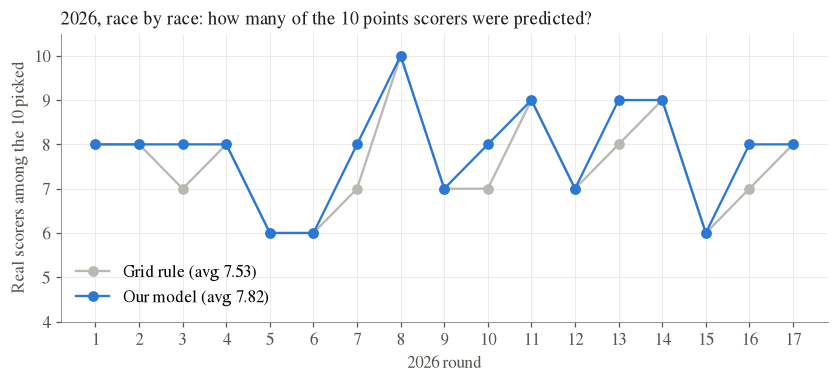

Model better in 5 races, equal in 12, worse in 0.


In [2]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(T.index, T['Grid rule'], 'o-', color=GREY, label=f"Grid rule (avg {T['Grid rule'].mean():.2f})")
ax.plot(T.index, T['Model'], 'o-', color=BLUE, label=f"Our model (avg {T['Model'].mean():.2f})")
ax.set_xticks(T.index); ax.set_xlabel('2026 round'); ax.set_ylabel('Real scorers among the 10 picked'); ax.set_ylim(4, 10.5); ax.legend(loc='lower left')
title(ax, '2026, race by race: how many of the 10 points scorers were predicted?'); save(fig, '06_2026'); plt.show()
print(f"Model better in {(T.Model > T['Grid rule']).sum()} races, equal in {(T.Model == T['Grid rule']).sum()}, worse in {(T.Model < T['Grid rule']).sum()}.")

### Monaco and other grid-dependent tracks (the professor's question)
*"Monaco is very grid dependent, and many GPs might be similar."* We group the 2020–2025 test races by track. A track's **grid dependence** is the share of its top-10 finishers who started in the top 10, measured on **2010–2019 only**, so the groups are fixed before looking at the test races.

,races,scorers_grid,scorers_model,duel_grid,duel_model,gain_scorers,gain_duels_pts
All races,131.0,7.710,7.870,0.755,0.774,0.160,1.947
Street circuits,34.0,7.706,7.765,0.754,0.768,0.059,1.391
Most grid-dependent third of tracks,34.0,7.618,7.912,0.747,0.780,0.294,3.351
Monaco,5.0,9.200,8.000,0.853,0.807,-1.200,-4.669


Most grid-dependent tracks (2010-2019): hungaroring, istanbul, mexico-city, montreal, monza, nurburgring, paul-ricard, shanghai, yas-marina
Monaco 2010-2019: 74% of top-10 finishers started top 10 (median track: 76%)


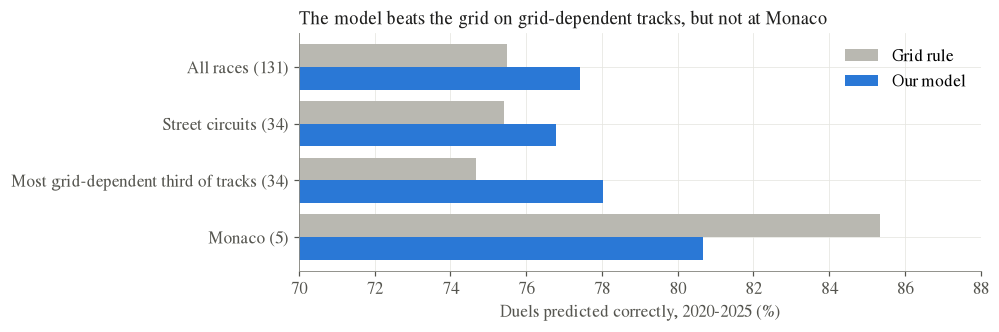

In [3]:
TR = S['tracks']
G = pd.DataFrame({k: v for k, v in TR.items() if isinstance(v, dict)}).T
G['gain_scorers'] = G.scorers_model - G.scorers_grid; G['gain_duels_pts'] = 100 * (G.duel_model - G.duel_grid)
display(G.round(3))
print('Most grid-dependent tracks (2010-2019):', ', '.join(TR['grid_dependent_tracks']))
print(f"Monaco 2010-2019: {TR['monaco_grid_dependence_2010_2019']:.0%} of top-10 finishers started top 10 (median track: {TR['grid_dependence_median_2010_2019']:.0%})")
fig, ax = plt.subplots(figsize=(8, 2.8)); y = np.arange(len(G))[::-1]
ax.barh(y + 0.2, G.duel_grid * 100, 0.4, color=GREY, label='Grid rule'); ax.barh(y - 0.2, G.duel_model * 100, 0.4, color=BLUE, label='Our model')
ax.set_yticks(y); ax.set_yticklabels([f"{n} ({int(r)})" for n, r in zip(G.index, G.races)]); ax.set_xlim(70, 88)
ax.set_xlabel('Duels predicted correctly, 2020-2025 (%)'); ax.legend(loc='upper right')
title(ax, 'The model beats the grid on grid-dependent tracks, but not at Monaco'); save(fig, '06_tracks'); plt.show()

**Reading.** At **Monaco the grid wins** (5 races): it names 9.2 of the 10 scorers against 8.0 for the model. Overtaking is almost impossible there, so any change the model makes to the grid order is a mistake. But Monaco is an exception, not a family: on the **third of tracks that depended most on the grid in 2010–2019** and on **street circuits**, the model still beats the grid. Monaco itself was *not* unusually grid-dependent in 2010–2019; it became so after 2021 (bigger cars), which is why a rule learnt from the past could not anticipate it.

### One model or two? (normal tracks vs grid-dependent tracks)
Instead of one logistic regression for every track, we train **two**: one on normal tracks and one on grid-dependent tracks (the top third of circuits by share of top-10 finishers who started in the top 10, measured on past races only). Each has its own weights $\theta$. Code: `f1duel/tracks.py`.

,Normal track,Grid-dependent track
grid,-0.96,-1.31
log_grid,0.23,0.24
quali_gap,-0.04,-0.00
practice_gap,-0.28,-0.27
car_perf,0.64,0.95
car_rel,-0.11,-0.18
tier_top,-0.08,-0.15
tier_back,-0.30,-0.10
intercept,-0.20,-0.16


,Races,Grid rule,One model,Two models,Cross-entropy one,Cross-entropy two
Test,,,,,,
2020-2025,131,7.710,7.870,7.870,0.482,0.485
2026,17,7.529,7.824,7.765,0.476,0.480


Grid-dependent tracks: Spain, Hungary, Saudi Arabia, Mexico, Miami, Monaco, Italy, France, China, Japan, Abu Dhabi


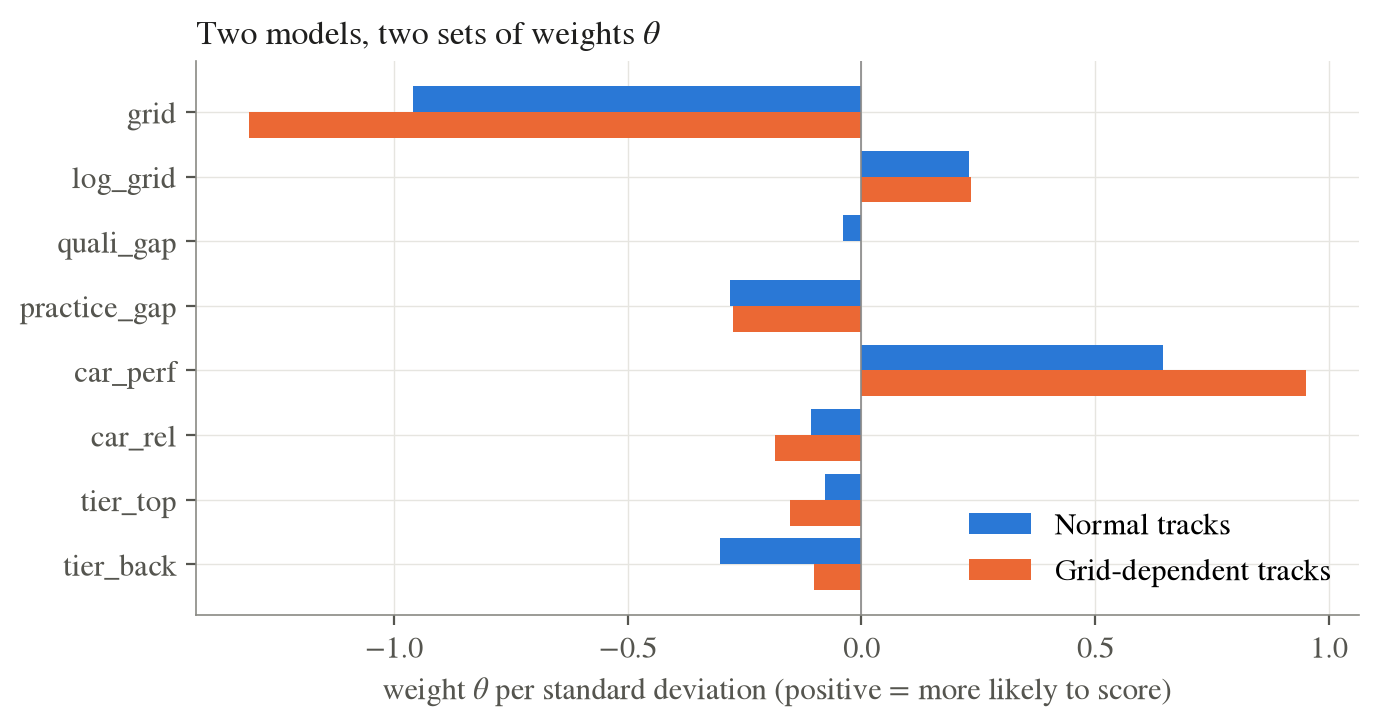

In [4]:
T = json.load(open('../results/tracks_summary.json'))
th = pd.DataFrame(T['final']['thetas']); display(th.round(2))
rows = [{'Test': t, 'Races': v['races'], 'Grid rule': v['named_grid'], 'One model': v['named_one'], 'Two models': v['named_two'],
         'Cross-entropy one': v['ce_one'], 'Cross-entropy two': v['ce_two']} for t in ('2020-2025', '2026') for v in [T[t]['All races']]]
display(pd.DataFrame(rows).set_index('Test').round(3))
print('Grid-dependent tracks:', ', '.join(x['gp'] for x in T['final']['grid_dependent_tracks']))
from IPython.display import Image; display(Image('../figures/06_two_models.png', width=650))

**Reading.** The weights really differ: on grid-dependent tracks the grid and the car performance weigh more. But each model learns from only part of the races, so its weights are noisier (bias–variance trade-off, session 4), and two models do not name more points scorers than one. We keep one model for the forecasts.

### The answer to our question

In [5]:
a, b = S['2020-2025'], S['2026']
print(f"""Could we predict who finishes ahead, better than the grid?
  * Points (top 10):  YES on 2020-2025: {a['scorers_named']['Logistic regression']:.2f} vs {a['scorers_named']['Grid rule']:.2f} scorers per race (gain +{a['gain_vs_grid']['Logistic regression'][0]:.2f}, 95% CI {a['gain_vs_grid']['Logistic regression'][1]:+.2f} to {a['gain_vs_grid']['Logistic regression'][2]:+.2f}).
                      2026: {b['scorers_named']['Logistic regression']:.2f} vs {b['scorers_named']['Grid rule']:.2f} (gain {b['gain_vs_grid']['Logistic regression'][0]:+.2f}, 95% CI {b['gain_vs_grid']['Logistic regression'][1]:+.2f} to {b['gain_vs_grid']['Logistic regression'][2]:+.2f}, 17 races).
  * Duels (A vs B):   YES: {a['duel']['after']['accuracy']:.1%} vs {a['duel']['after']['grid_rule_accuracy']:.1%} (2020-2025) and {b['duel']['after']['accuracy']:.1%} vs {b['duel']['after']['grid_rule_accuracy']:.1%} (2026); both gains significant.
  * Winner:           the favourite is usually the pole sitter ({a['winner']['favourite_is_pole']:.0%} of races), so it wins as often ({a['winner']['favourite_won']:.0%}); the gain is in calibrated chances (log-loss {a['winner']['logloss']:.2f} vs {a['winner']['logloss_gridrate_baseline']:.2f}).
  * Before qualifying: worse than the grid. Saturday matters most.""")

Could we predict who finishes ahead, better than the grid?
  * Points (top 10):  YES on 2020-2025: 7.87 vs 7.71 scorers per race (gain +0.16, 95% CI +0.02 to +0.30).
                      2026: 7.82 vs 7.53 (gain +0.29, 95% CI +0.12 to +0.53, 17 races).
  * Duels (A vs B):   YES: 77.4% vs 75.5% (2020-2025) and 81.2% vs 78.9% (2026); both gains significant.
  * Winner:           the favourite is usually the pole sitter (92% of races), so it wins as often (54%); the gain is in calibrated chances (log-loss 1.38 vs 1.56).
  * Before qualifying: worse than the grid. Saturday matters most.


### Next: the live test
The real test is the races that have not happened yet: **United States (25 Oct), Mexico City (1 Nov), São Paulo (8 Nov), Las Vegas (22 Nov), Qatar (29 Nov), Abu Dhabi (6 Dec)**. Before each one, `python -m f1duel.forecast` publishes the predictions (committed to GitHub before the start, so the timestamp proves it), and the website shows *model vs reality* after each race.